# Mumbai Air Quality Forecasting — Starter Notebook

**A first working baseline, from CSV files to a complete submission.**

Predict hourly **PM2.5 concentration in µg/m³** at four monitoring stations in Mumbai.
Each test row describes one station and one hour. The target is a concentration,
not an air quality index or a class.

In this notebook you will:

1. Load the challenge files and understand their timestamps.
2. Explore a few useful patterns in the training observations.
3. Check a simple model on two later days, with a reporting-delay gap.
4. Create and validate `submission.csv` for **every test ID**.
5. Find practical ideas to try next.

We train a **RandomForestRegressor** using station and calendar features, then
call `predict` to generate forecasts. We use pandas, NumPy, Matplotlib and
scikit-learn, which are available in Google Colab.
No API key, additional dataset or organizer answer file is needed.

## 1. Open the data

Download these four files from the challenge's Data page:

- **Train.csv** — historical hourly observations; `pm25` is the target.
- **Test.csv** — the station-hours you need to predict, without targets.
- **SampleSubmission.csv** — the required `ID,Target` output format.
- **Stations.csv** — station names, coordinates and identifiers.

Keep **DataDictionary.txt** nearby for the field definitions.
**AdditionalHistory.zip** is optional and is not used in this starter.

**Google Colab:** run the next cell and upload the four CSV files when prompted.
**Local Jupyter:** put the CSV files beside the notebook, or change `DATA_DIR` below.

A download suffix such as `Test(2).csv` is accepted. Keep just **one version of
each file** in the working folder, using files downloaded together.

In [19]:
%matplotlib inline
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('.')
FILE_STEMS = ['Train', 'Test', 'SampleSubmission', 'Stations']

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def find_csv(stem):
    pattern = re.compile(re.escape(stem) + r'(?:\s*\(\d+\))?\.csv', re.IGNORECASE)
    matches = [p for p in DATA_DIR.glob('*.csv') if pattern.fullmatch(p.name)]
    if len(matches) > 1:
        raise ValueError(f'Keep only one current {stem} CSV. Found: {[p.name for p in matches]}')
    return matches[0] if matches else None

if IN_COLAB and any(find_csv(stem) is None for stem in FILE_STEMS):
    print('Upload Train.csv, Test.csv, SampleSubmission.csv and Stations.csv.')
    files.upload()

paths = {stem: find_csv(stem) for stem in FILE_STEMS}
missing = [stem + '.csv' for stem, path in paths.items() if path is None]
if missing:
    raise FileNotFoundError(f'Missing {missing}. Add the current CSV files to DATA_DIR and rerun.')

train = pd.read_csv(paths['Train'], dtype={'location_id': 'string', 'sensor_id': 'string'})
test = pd.read_csv(paths['Test'], dtype={'ID': 'string', 'location_id': 'string', 'sensor_id': 'string'})
sample = pd.read_csv(paths['SampleSubmission'], dtype={'ID': 'string'})
stations = pd.read_csv(paths['Stations'], dtype={'location_id': 'string', 'selected_sensor': 'string'})

for name, frame in [('Train', train), ('Test', test), ('SampleSubmission', sample), ('Stations', stations)]:
    print(f'{name}: {len(frame):,} rows — loaded from {paths[name].name}')
display(train.head(3))
display(test.head(3))

Train: 47,116 rows — loaded from Train.csv
Test: 2,592 rows — loaded from Test.csv
SampleSubmission: 2,592 rows — loaded from SampleSubmission.csv
Stations: 4 rows — loaded from Stations.csv


,timestamp_ist,mean,count,available_at,pm25,location_id,sensor_id,station_name,series_id,flag_high_1000
0,2025-02-19 03:00:00+05:30,81.3750,4.0,2025-02-23 00:00:40+05:30,81.3750,11606,12236418,"Borivali East, Mumbai - IITM",openaq:12236418,False
1,2025-02-19 04:00:00+05:30,73.2675,4.0,2025-02-23 00:00:40+05:30,73.2675,11606,12236418,"Borivali East, Mumbai - IITM",openaq:12236418,False
2,2025-02-19 05:00:00+05:30,66.1150,4.0,2025-02-23 00:00:40+05:30,66.1150,11606,12236418,"Borivali East, Mumbai - IITM",openaq:12236418,False


,ID,location_id,sensor_id,target_start_ist,target_end_ist,scoring_block,unit
0,MUM_11611_20261027T0100_IST,11611,12236426,2026-10-27T00:00:00+05:30,2026-10-27T01:00:00+05:30,public,µg/m³
1,MUM_11611_20261027T0200_IST,11611,12236426,2026-10-27T01:00:00+05:30,2026-10-27T02:00:00+05:30,public,µg/m³
2,MUM_11611_20261027T0300_IST,11611,12236426,2026-10-27T02:00:00+05:30,2026-10-27T03:00:00+05:30,public,µg/m³


## 2. Align the hours and check the files

All challenge intervals use **Indian Standard Time, IST (UTC+05:30)**.

- Train's `timestamp_ist` marks the **end** of an observation hour.
- Test explicitly supplies `target_start_ist` and `target_end_ist`.
- For example, a Train timestamp of **22 October 00:00** describes the hour
  **21 October 23:00–22 October 00:00**.

We subtract one hour from the Train timestamp and use the **start hour** for
both Train and Test. This avoids shifting the daily pattern by one hour.

`mean` duplicates the target `pm25`; it must not become an input feature.
`count`, `flag_high_1000` and `available_at` describe observed data or provenance;
their future values are not model inputs. `scoring_block` describes evaluation
allocation and is also not a pollution predictor. We create station and calendar
features from information known for every requested test hour.

In [20]:
IST = 'Asia/Kolkata'

def as_ist(values):
    return pd.to_datetime(values, utc=True).dt.tz_convert(IST)

train['hour_end'] = as_ist(train['timestamp_ist'])
train['hour_start'] = train['hour_end'] - pd.Timedelta(hours=1)
test['hour_start'] = as_ist(test['target_start_ist'])
test['hour_end'] = as_ist(test['target_end_ist'])
train['hour'] = train['hour_start'].dt.hour
test['hour'] = test['hour_start'].dt.hour
train = train.sort_values(['location_id', 'hour_end']).reset_index(drop=True)

assert len(stations) == 4, 'Expected the four target stations.'
assert train['pm25'].notna().all() and np.isfinite(train['pm25']).all()
assert (train['pm25'] >= 0).all()
assert not train.duplicated(['sensor_id', 'hour_end']).any()
assert test['ID'].notna().all() and test['ID'].is_unique
assert sample['ID'].notna().all() and sample['ID'].is_unique
assert list(sample.columns) == ['ID', 'Target']
assert test['ID'].tolist() == sample['ID'].tolist(), 'Use Test and SampleSubmission from the same release.'
assert test['location_id'].isin(stations['location_id']).all()
assert (test['hour_end'] - test['hour_start']).eq(pd.Timedelta(hours=1)).all()

station_names = stations.set_index('location_id')['station_name'].to_dict()
print(f'Latest available training hour ends: {train["hour_end"].max()}')
print(f'Every submission must contain all {len(test):,} test IDs, in the sample order.')
display(stations[['location_id', 'station_name', 'latitude', 'longitude']])

Latest available training hour ends: 2026-10-22 00:00:00+05:30
Every submission must contain all 2,592 test IDs, in the sample order.


,location_id,station_name,latitude,longitude
0,11611,"Malad West, Mumbai - IITM",19.197090,72.822040
1,3409511,"Shivaji Nagar, Mumbai - BMC",19.060498,72.923356
2,11606,"Borivali East, Mumbai - IITM",19.232410,72.868950
3,3409510,"Byculla, Mumbai - BMC",18.976700,72.838000


## 3. Take a quick look

Check each station's observation count and date range. Counts can differ because
some observations are missing. Missing hours are **not zero pollution**.

The charts show daily averages and a recent daily pattern. Daily averages use
the available observations only; they are descriptive, not complete daily targets.

,station,observations,first_hour_end,last_hour_end,average_pm25
location_id,,,,,
11606,"Borivali East, Mumbai - IITM",11921,2025-02-19 03:00:00+05:30,2026-10-22 00:00:00+05:30,48.122934
11611,"Malad West, Mumbai - IITM",12020,2025-02-19 03:00:00+05:30,2026-10-22 00:00:00+05:30,25.463051
3409510,"Byculla, Mumbai - BMC",11362,2025-02-19 03:00:00+05:30,2026-10-22 00:00:00+05:30,26.849079
3409511,"Shivaji Nagar, Mumbai - BMC",11813,2025-02-19 03:00:00+05:30,2026-10-22 00:00:00+05:30,75.374185


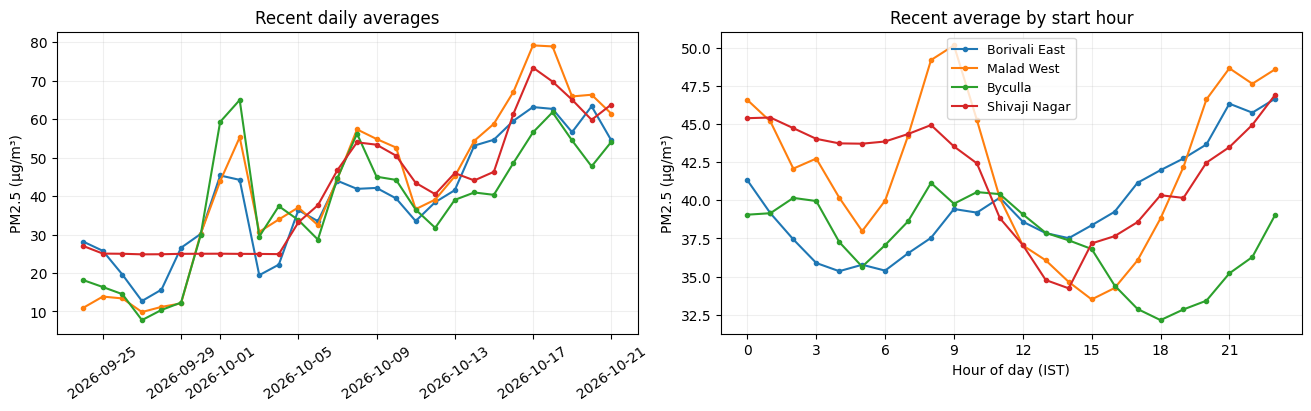

In [21]:
overview = train.groupby('location_id').agg(
    observations=('pm25', 'size'),
    first_hour_end=('hour_end', 'min'),
    last_hour_end=('hour_end', 'max'),
    average_pm25=('pm25', 'mean'),
)
overview.insert(0, 'station', overview.index.map(station_names))
display(overview)

recent = train.loc[train['hour_end'] > train['hour_end'].max() - pd.Timedelta(days=28)].copy()
recent['day'] = recent['hour_start'].dt.floor('D')
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for location, group in recent.groupby('location_id'):
    short_name = station_names[location].split(',')[0]
    daily = group.groupby('day')['pm25'].mean()
    hourly = group.groupby('hour')['pm25'].mean()
    axes[0].plot(daily.index, daily.values, marker='.', label=short_name)
    axes[1].plot(hourly.index, hourly.values, marker='.', label=short_name)
axes[0].set(title='Recent daily averages', ylabel='PM2.5 (µg/m³)')
axes[0].tick_params(axis='x', rotation=35)
axes[1].set(title='Recent average by start hour', xlabel='Hour of day (IST)', ylabel='PM2.5 (µg/m³)')
axes[1].set_xticks(range(0, 24, 3))
axes[1].legend(fontsize=9)
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

## 4. Make a time-based validation split

For a local check, hold out the **latest two complete calendar days** represented
in Train. Use only earlier observations to fit the model.

Measurements arrive with a delay. Here we leave a **three-day gap** between the
latest training observation we allow and the start of the validation period.
Imagine issuing the forecast at the start of validation with that delayed history.
This is a conservative starting assumption; actual delivery timing varies.

This is an **approximate historical backtest**, not the live leaderboard. It does
not reconstruct exactly when each historical value was first available.
`available_at` is not a verified first-publication timestamp for all rows.
We do not use it as a model feature or pretend this is a historical release log.

In [22]:
VALIDATION_DAYS = 2
REPORTING_GAP_DAYS = 3
TRAIN_WINDOW_DAYS = 90

# At midnight the previous calendar day has ended. If the latest observation
# is part-way through a day, leave that incomplete day out of validation.
validation_end = train['hour_end'].max().normalize()
validation_start = validation_end - pd.Timedelta(days=VALIDATION_DAYS)
history_cutoff = validation_start - pd.Timedelta(days=REPORTING_GAP_DAYS)

history = train.loc[train['hour_end'] <= history_cutoff].copy()
history = history.loc[history['hour_end'] > history_cutoff - pd.Timedelta(days=TRAIN_WINDOW_DAYS)]
validation = train.loc[
    (train['hour_start'] >= validation_start) &
    (train['hour_start'] < validation_end)
].copy()

assert not history.empty and not validation.empty
assert history['hour_end'].max() <= history_cutoff < validation_start
assert validation['location_id'].isin(history['location_id']).all()

print(f'Forecast issued at: {validation_start}')
print(f'Latest permitted input hour ends: {history_cutoff}')
print(f'Validation intervals: {validation_start} to {validation_end} (end exclusive)')
print(f'Observed validation station-hours: {len(validation)} / {len(stations) * 24 * VALIDATION_DAYS}')
display(validation.groupby('location_id').size().rename('observed_validation_hours').to_frame())

Forecast issued at: 2026-10-20 00:00:00+05:30
Latest permitted input hour ends: 2026-10-17 00:00:00+05:30
Validation intervals: 2026-10-20 00:00:00+05:30 to 2026-10-22 00:00:00+05:30 (end exclusive)
Observed validation station-hours: 181 / 192


,observed_validation_hours
location_id,
11606,48
11611,43
3409510,44
3409511,46


## 5. Create features and train a Random Forest

This is supervised learning: **X** contains the input features and **y** contains
the observed PM2.5 target. We use station, hour, weekday, month and day of year.
All these features are known before the target measurement happens.

`OneHotEncoder` turns station names/IDs into separate indicator columns, so the
model does not treat the numeric identifiers as a pollution scale.

A Random Forest trains a collection of decision trees on historical examples
and combines their predictions. The pipeline keeps station encoding and the
regressor together. **`model.fit(X_train, y_train)` is the training step.**

We use 100 trees, limit their depth and set a random seed. This is a small,
ordinary starting model; these settings have not been tuned to win the challenge.
The starting training window is the most recent 90 available days. Older data
remain in Train and can be explored in your own experiments.

[RandomForestRegressor documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

def make_features(rows):
    time = rows['hour_start']
    return pd.DataFrame({
        'location_id': rows['location_id'].astype(str),
        'hour': time.dt.hour,
        'day_of_week': time.dt.dayofweek,
        'month': time.dt.month,
        'day_of_year': time.dt.dayofyear,
    }, index=rows.index)

X_train = make_features(history)
y_train = history['pm25']
X_valid = make_features(validation)
y_valid = validation['pm25']

preprocessor = ColumnTransformer(
    [('station', OneHotEncoder(handle_unknown='ignore'), ['location_id'])],
    remainder='passthrough',
)
model = Pipeline([
    ('features', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1,
    )),
])

model.fit(X_train, y_train)
print(f'Random Forest trained on {len(X_train):,} observations.')
display(X_train.head())

Random Forest trained on 7,033 observations.


,location_id,hour,day_of_week,month,day_of_year
10147,11606,1,6,7,200
10148,11606,2,6,7,200
10149,11606,3,6,7,200
10150,11606,4,6,7,200
10151,11606,5,6,7,200


## 6. Measure performance with RMSE

**Root Mean Squared Error (RMSE)** measures the difference between predictions
and observations. It squares each error, averages the squared errors, and takes
the square root. Larger mistakes receive more weight. **Lower is better**;
the score has the same units as the target, µg/m³.

We predict with **`model.predict(X_valid)`** and compare the result with a
simple station-mean reference. Both use the same permitted training history.
Each observed station-hour has equal weight. No missing validation target is invented.

[Zindi's introduction to RMSE](https://zindi.world/learn/zindi-error-metric-series-what-is-root-mean-square-error-rmse)

In [24]:
def rmse(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return float(np.sqrt(np.mean((actual - predicted) ** 2)))

station_means = history.groupby('location_id')['pm25'].mean()
validation['station_mean_prediction'] = validation['location_id'].map(station_means).fillna(history['pm25'].mean())
validation['prediction'] = model.predict(X_valid)

scores = pd.DataFrame([
    {'model': 'Station mean (reference)', 'validation_rmse': rmse(y_valid, validation['station_mean_prediction'])},
    {'model': 'Random Forest', 'validation_rmse': rmse(y_valid, validation['prediction'])},
])
display(scores.round(3))

per_station = []
for location, group in validation.groupby('location_id'):
    per_station.append({
        'station': station_names[location],
        'observed_hours': len(group),
        'random_forest_rmse': rmse(group['pm25'], group['prediction']),
    })
display(pd.DataFrame(per_station).round(3))
print('This is one local backtest. A more detailed model is not guaranteed to win on every window.')

,model,validation_rmse
0,Station mean (reference),39.978
1,Random Forest,9.064


,station,observed_hours,random_forest_rmse
0,"Borivali East, Mumbai - IITM",48,8.690
1,"Malad West, Mumbai - IITM",43,8.669
2,"Byculla, Mumbai - BMC",44,9.436
3,"Shivaji Nagar, Mumbai - BMC",46,9.438


This is one local backtest. A more detailed model is not guaranteed to win on every window.


## 7. Look at the predictions

Inspect a station before adding more complexity. The forest has learned from
station and calendar features, but has no recent-pollution or weather inputs.
Look for peaks or changing conditions it misses. The chart uses held-out predictions.

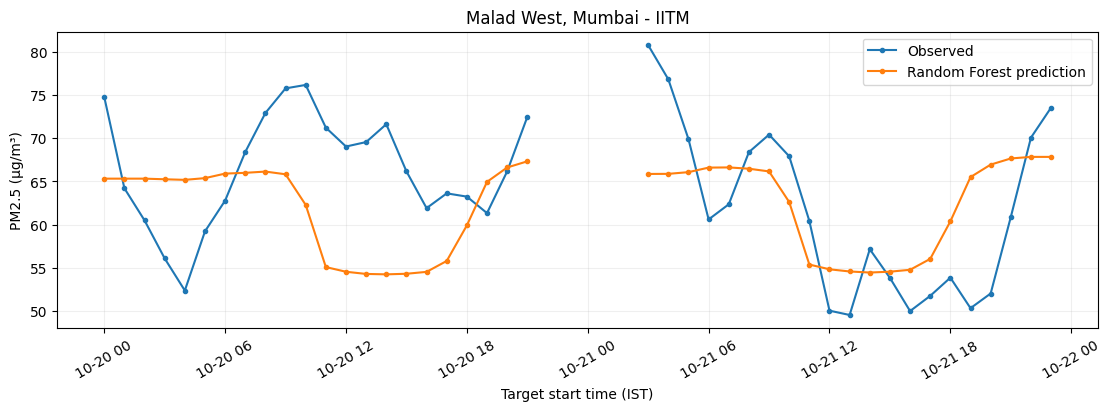

In [25]:
station_to_plot = stations['location_id'].iloc[0]
example = validation.loc[validation['location_id'] == station_to_plot].sort_values('hour_start')
# Keep missing observations visible as breaks in the lines.
example = example.set_index('hour_start').reindex(
    pd.date_range(validation_start, validation_end, freq='h', inclusive='left')
)
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
ax.plot(example.index, example['pm25'], marker='o', markersize=3, label='Observed')
ax.plot(example.index, example['prediction'], marker='.', label='Random Forest prediction')
ax.set(title=station_names[station_to_plot], xlabel='Target start time (IST)', ylabel='PM2.5 (µg/m³)')
ax.tick_params(axis='x', rotation=30)
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 8. Refit on the released training data and predict every test row

Validation used a restricted history so that we could check the approach.
For the submission, refit the same pipeline on the **most recent 90 available
days in the latest released Train file**, then predict every Test row.

The Test grid is fixed throughout the competition. Public scoring moves between
announced two-day windows, and newly released observations can be used to update
the model. **Always predict every ID**, including past, future and currently
unscored rows. The organizer chooses which subset contributes to each score.

In [26]:
final_history = train.loc[
    train['hour_end'] > train['hour_end'].max() - pd.Timedelta(days=TRAIN_WINDOW_DAYS)
]
X_all = make_features(final_history)
y_all = final_history['pm25']
X_test = make_features(test)

model.fit(X_all, y_all)
test_predictions = model.predict(X_test)

print(f'Refit Random Forest on {len(X_all):,} observations from the last {TRAIN_WINDOW_DAYS} available days.')
print(f'Latest input hour ends: {train["hour_end"].max()}')
print(f'Predicted {len(test_predictions):,} station-hours.')

Refit Random Forest on 7,036 observations from the last 90 available days.
Latest input hour ends: 2026-10-22 00:00:00+05:30
Predicted 2,592 station-hours.


## 9. Build and check submission.csv

Start from SampleSubmission to preserve its ID order. Map predictions by ID,
fill every Target, and save **exactly `ID,Target`**, without a pandas index column.
All predictions must be finite and non-negative. The template's example values
are placeholders; this cell replaces every Target with a model prediction.

In [27]:
predictions_by_id = pd.Series(test_predictions, index=test['ID'])
submission = sample.copy()
submission['Target'] = submission['ID'].map(predictions_by_id)

assert list(submission.columns) == ['ID', 'Target']
assert submission['ID'].tolist() == sample['ID'].tolist()
assert len(submission) == len(test)
assert submission['ID'].is_unique
assert submission['Target'].notna().all()
assert np.isfinite(submission['Target']).all()
assert (submission['Target'] >= 0).all()

OUTPUT_FILE = Path('submission.csv')
submission.to_csv(OUTPUT_FILE, index=False)
saved = pd.read_csv(OUTPUT_FILE, dtype={'ID': 'string'})
assert saved['ID'].tolist() == sample['ID'].tolist()
assert list(saved.columns) == ['ID', 'Target'] and np.isfinite(saved['Target']).all()

display(submission.head())
print(f'Saved {OUTPUT_FILE.name}: {len(submission):,} rows. All submission checks passed.')
if IN_COLAB:
    files.download(str(OUTPUT_FILE))

,ID,Target
0,MUM_11611_20261027T0100_IST,65.918175
1,MUM_11611_20261027T0200_IST,65.918175
2,MUM_11611_20261027T0300_IST,65.782705
3,MUM_11611_20261027T0400_IST,65.684386
4,MUM_11611_20261027T0500_IST,65.436035


Saved submission.csv: 2,592 rows. All submission checks passed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. When the challenge data are updated

1. Download the newly released **Train.csv** and keep one current copy.
2. Rerun the notebook from the top. Check the latest training timestamp printed above.
3. Create a fresh full-length `submission.csv`; keep the original Test and SampleSubmission IDs.
4. Upload the new file to Zindi before the final deadline.

The public leaderboard uses **only its active two-day window**. An update
replaces the previous window, so scores from different windows are not directly
comparable. Private ranking uses the announced final private period.
Check the challenge page for the official schedule and submission-selection policy.

The initial public period, **22–23 October**, is excluded from the launch Train.
Use only released participant training data here; the notebook does not fetch
targets for evaluation periods or read any organizer scoring files.

## What to try next

- **Stronger models:** explore gradient boosting models such as CatBoost, LightGBM or XGBoost.
- **Time patterns:** consider models and features that capture recent pollution trends, seasonality and differences between stations.
- **Ensembles:** combining models with different strengths may improve accuracy and stability.
- **Additional data:** weather forecasts, festival calendars and environmental datasets may provide useful context.
- **Validation:** compare approaches across several historical periods, using only information available at forecast time.